# 00 · Define what agreement means

The central object is a profile of agreements among observables. We hold representations explicit and interpret decisions relative to known labels. This foundation stage measures exact mathematical properties and controlled performance. Its primary outcomes are resolving power and interpretable failures.

## Setup
All examples use synthetic configurations. See THEORY.md for definitions, assumptions and proofs.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import *
from observables.patterns import *
from observables.images import *
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,3.5),'figure.dpi':110,
                    'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
def unit_circle(angles):
    return np.column_stack([np.cos(angles),np.sin(angles)])
SEED=41

## Configuration, observables and comparison
Write $\mathcal C_A=\{(r_i,h_i,w_i)\}_{i=1}^N$, with normalized nonnegative weights. Positions live in a specified domain and features in a common coordinate system. Define $O_j(A)$ before comparing objects. Here the descriptive agreement is
$S_j(A,B)=1-\|O_j(A)-O_j(B)\|/(\|O_j(A)\|+\|O_j(B)\|)$.
Both numerically zero gives agreement 1, with zero informative signal. We always retain observable magnitude alongside agreement. This bounded ratio is a reporting convention; it has no universal probability interpretation. Angular kernel distances have a separate derivation.

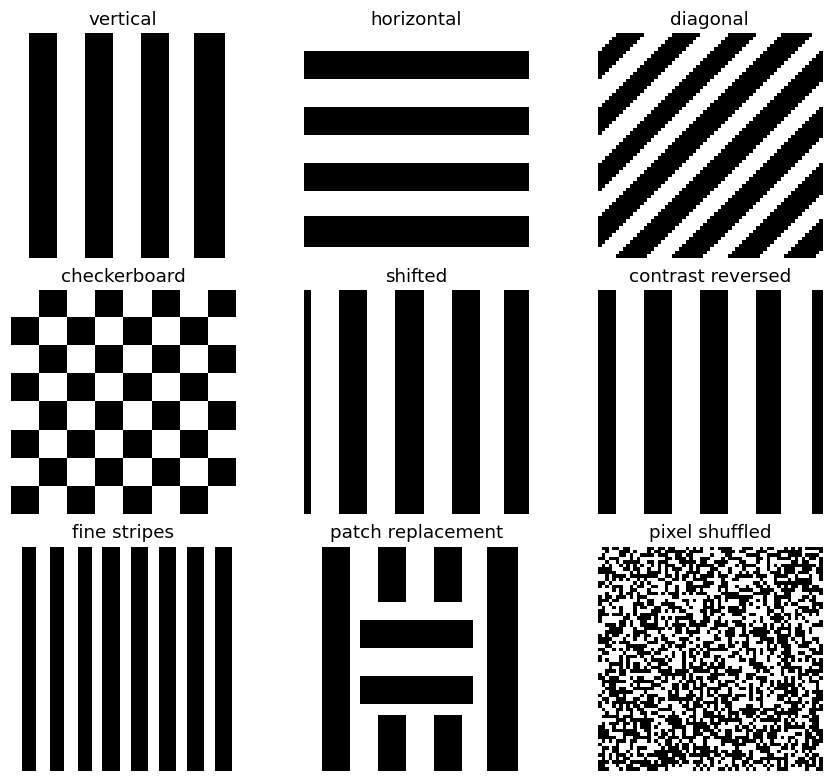

In [3]:
patterns=motif_gallery()
fig,axes=plt.subplots(3,3,figsize=(8,7))
for ax,(name,im) in zip(axes.flat,patterns.items()):
    ax.imshow(im,cmap='gray',vmin=-1,vmax=1);ax.set_title(name);ax.axis('off')
show('00_patterns')

## Questions fixed before experiments
1. Which observables distinguish equal means with different orientation distributions?
2. Which observables retain positional order after global pooling?
3. Which different configurations share exactly the same pair correlations?
4. Which invariances help a task and erase distinctions needed by another task?
5. How much apparent order arises from finite samples?

Periodic boundaries and 64 × 64 synthetic images are explicit choices. The symbolic sequence examples are an abstract analogue of ordered tokens. They carry no language semantics.

In [5]:
a=patterns['vertical']
rows=[]
for name,im in patterns.items():
    angular,energy=orientation(im)
    rows.append((name,im.mean(),im.var(),energy,*np.abs(angular)))
display(pd.DataFrame(rows,columns=['pattern','mean','variance','mean gradient magnitude','|m1|','|m2|','|m4|']).round(4))

,pattern,mean,variance,mean gradient magnitude,|m1|,|m2|,|m4|
0,vertical,-0.0312,0.9990,0.2500,0.0,1.0000,1.0000
1,horizontal,-0.0312,0.9990,0.2500,0.0,1.0000,1.0000
2,diagonal,-0.0942,0.9911,0.3544,0.0,0.9917,0.9835
3,checkerboard,0.0000,1.0000,0.4634,0.0,0.0000,0.6185
4,shifted,-0.0312,0.9990,0.2500,0.0,1.0000,1.0000
5,contrast reversed,0.0312,0.9990,0.2500,0.0,1.0000,1.0000
6,fine stripes,-0.1562,0.9756,0.5000,0.0,1.0000,1.0000
7,patch replacement,-0.0312,0.9990,0.2790,0.0,0.4481,0.9604
8,pixel shuffled,-0.0312,0.9990,0.8467,0.0,0.0150,0.1845


## Interpretation
The image representation uses gradient **normals**. Rotating every normal by 90° gives edge tangents. Pair comparisons are unchanged when this rotation is applied to both objects, but the reported director axis changes. Near-zero gradients have no defined orientation and receive zero orientation weight. Magnitude weighting, edge activity and intensity statistics remain explicit.

The project has a planned later stage for learned patch descriptors and whole-object embeddings. The current notebooks establish the controlled foundation.